# Taller 1 — Teoría de Aprendizaje de Máquina
## Clasificación supervisada, vecinos cercanos y evaluación de modelos

**Juan David Villota**

**Semilla:** `42`

| Punto | Qué se comprueba en el cuaderno |
|-------|---------------------------------|
| **1.1** | Frontera $w^\top x+b=0$ y clase asignada a cuatro puntos |
| **1.2** | Identidad del margen tras una actualización del perceptrón |
| **1.3** | Un paso numérico del perceptrón |
| **2.1** | Distancias y votación k-NN para $k=1,3,5$ |
| **2.2** | `make_moons`, exactitud y regiones de decisión |
| **3** | Matriz de confusión, métricas y verificación con scikit-learn |

Los cálculos manuales y las demostraciones completas están en el documento PDF.
Aquí se reproducen y se comprueban numéricamente.

## 0. Preparación

Imports, semilla fija y carpeta donde se guardan las figuras que usa el documento.

### Explicación — Preparación

- **`numpy`**: vectores, matrices y cálculos numéricos.
- **`matplotlib`**: figuras; se guardan en `figuras/` como PDF vectorial.
- **`SEED = 42`**: la misma semilla del enunciado para `make_moons`; todo lo aleatorio del cuaderno la reutiliza.
- **`FIG_DIR.mkdir(exist_ok=True)`**: el cuaderno es reproducible desde su carpeta aunque `figuras/` no exista.

**Qué mirar:** que se impriman las versiones y la semilla.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path

np.set_printoptions(precision=4, suppress=True, linewidth=100)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

SEED = 42
FIG_DIR = Path("figuras")
FIG_DIR.mkdir(exist_ok=True)

print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Semilla:", SEED)

NumPy: 2.5.3
scikit-learn: 1.9.1
Semilla: 42


---
# 1. Clasificación lineal y algoritmo del perceptrón

**Modelo.** Para $x\in\mathbb{R}^2$ y etiquetas $y\in\{-1,+1\}$,

$$
\hat{y} =
\begin{cases}
+1, & w^\top x + b > 0,\\
-1, & w^\top x + b \leq 0.
\end{cases}
$$

La frontera de decisión es la recta $w^\top x+b=0$. El signo de
$s(x)=w^\top x+b$ es lo único que decide la clase; la magnitud $|s(x)|$ mide
qué tan lejos está el punto de la frontera.

### Explicación — 1.1 Frontera y predicciones

Con $w=(1,2)^\top$ y $b=-3$, la frontera es

$$
x_1 + 2x_2 - 3 = 0
\quad\Longleftrightarrow\quad
x_2 = \frac{3-x_1}{2}.
$$

Para cada punto se evalúa $s(x)=w^\top x+b$ y se aplica la regla: $s(x)>0$
asigna $+1$ y $s(x)\leq 0$ asigna $-1$. La última columna es la distancia
euclidiana a la recta, $|s(x)|/\lVert w\rVert$.

**Qué mirar:** que $x_3=(2,1)$ sea el punto positivo más cercano a la frontera
($s=1$) y que $x_1=(0,0)$ sea el más alejado del lado negativo ($s=-3$).

In [2]:
w = np.array([1.0, 2.0])
b = -3.0

X = np.array([[0.0, 0.0],
              [1.0, 0.0],
              [2.0, 1.0],
              [3.0, 1.0]])
y = np.array([-1, -1, 1, 1])          # etiquetas verdaderas

s = X @ w + b                          # puntuación s(x)
y_hat = np.where(s > 0, 1, -1)         # regla de predicción

print(f"{'punto':>12} {'s(x)':>7} {'y':>3} {'y_hat':>6} {'dist':>7}")
for xi, si, yi, pi in zip(X, s, y, y_hat):
    dist = abs(si) / np.linalg.norm(w)
    print(f"({xi[0]:4.1f},{xi[1]:4.1f}) {si:7.2f} {yi:3d} {pi:6d} {dist:7.4f}")

       punto    s(x)   y  y_hat    dist
( 0.0, 0.0)   -3.00  -1     -1  1.3416
( 1.0, 0.0)   -2.00  -1     -1  0.8944
( 2.0, 1.0)    1.00   1      1  0.4472
( 3.0, 1.0)    2.00   1      1  0.8944


### Explicación — Figura 1.1

- La recta negra es $w^\top x+b=0$.
- La zona azul es la región $+1$ y la roja la región $-1$.
- La flecha es el vector normal $w=(1,2)$: apunta siempre hacia el lado positivo.
- Cada punto lleva su coordenada; el color indica su clase verdadera.

**Qué mirar:** que los cuatro puntos queden del lado que predice la tabla.

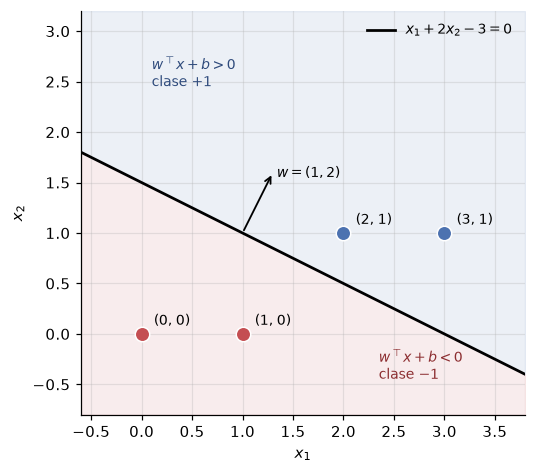

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))

xs = np.linspace(-0.6, 3.8, 200)
frontera = (3 - xs) / 2

ax.plot(xs, frontera, color="black", lw=1.8,
        label=r"$x_1+2x_2-3=0$")
ax.fill_between(xs, frontera, 3.2, color="#4C72B0", alpha=0.10)
ax.fill_between(xs, -0.8, frontera, color="#C44E52", alpha=0.10)

ax.text(0.10, 2.45, r"$w^\top x+b>0$" + "\nclase $+1$",
        color="#2F4B7C", fontsize=9)
ax.text(2.35, -0.45, r"$w^\top x+b<0$" + "\nclase $-1$",
        color="#8C2D30", fontsize=9)

for xi, yi in zip(X, y):
    color = "#4C72B0" if yi > 0 else "#C44E52"
    ax.scatter(*xi, s=90, color=color, edgecolor="white", zorder=5)
    ax.annotate(f"({xi[0]:.0f}, {xi[1]:.0f})", xi,
                textcoords="offset points", xytext=(8, 6), fontsize=9)

ax.annotate("", xy=(1.30, 1.60), xytext=(1.0, 1.0),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
ax.text(1.34, 1.55, r"$w=(1,2)$", fontsize=9)

ax.set_xlim(-0.6, 3.8)
ax.set_ylim(-0.8, 3.2)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_aspect("equal")
ax.legend(loc="upper right", fontsize=9, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "p1_frontera.pdf", bbox_inches="tight")
plt.show()

## 1.2 Actualización del perceptrón

Si $(x_i,y_i)$ está mal clasificada, la regla es

$$
w_{\text{nuevo}} = w + \eta\,y_i x_i,
\qquad
b_{\text{nuevo}} = b + \eta\,y_i,
\qquad \eta>0.
$$

El margen de la observación es $m_i=y_i\,(w^\top x_i+b)$. Sustituyendo la
actualización y usando $y_i^2=1$:

$$
\begin{aligned}
m_{i,\text{nuevo}}
&= y_i\bigl(w_{\text{nuevo}}^\top x_i+b_{\text{nuevo}}\bigr)\\
&= y_i\bigl((w+\eta y_i x_i)^\top x_i+b+\eta y_i\bigr)\\
&= y_i(w^\top x_i+b)+\eta y_i^2\,x_i^\top x_i+\eta y_i^2\\
&= m_i+\eta\bigl(\lVert x_i\rVert_2^2+1\bigr).
\end{aligned}
$$

**Lectura.** El margen de la observación corregida siempre **aumenta** en
$\eta(\lVert x_i\rVert^2+1)>0$, sin importar el valor actual de $w$ y $b$. Pero
el aumento es fijo: si el margen era muy negativo, una sola actualización puede
no volverlo positivo. Por eso el perceptrón requiere varias pasadas.

**Qué mirar:** que el incremento observado coincida con la fórmula.

In [4]:
rng = np.random.default_rng(SEED)
eta = 0.3
errores = []

for _ in range(5):
    w = rng.normal(size=2)
    b = rng.normal()
    x = rng.normal(size=2)
    y = 1.0

    m = y * (w @ x + b)
    w_new = w + eta * y * x
    b_new = b + eta * y
    m_new = y * (w_new @ x + b_new)

    errores.append(abs((m_new - m) - eta * (x @ x + 1)))

print("incremento observado (último caso):", f"{m_new - m:.10f}")
print("eta*(||x||^2+1)  (último caso):", f"{eta * (x @ x + 1):.10f}")
print("error máximo en 5 casos:", f"{max(errores):.2e}")

incremento observado (último caso): 0.3622032252
eta*(||x||^2+1)  (último caso): 0.3622032252
error máximo en 5 casos: 2.22e-16


## 1.3 Ejercicio numérico

Con $w=(0,0)^\top$, $b=0$, $\eta=0.5$, $x=(2,1)^\top$ y $y=+1$:

$$
s(x)=w^\top x+b=0
\quad\Longrightarrow\quad
\hat{y}=-1\neq +1,
$$

así que **sí** corresponde actualizar:

$$
w_{\text{nuevo}}=(0,0)+0.5\cdot 1\cdot(2,1)=(1,0.5),
\qquad
b_{\text{nuevo}}=0+0.5=0.5.
$$

El margen antes era $m=0$ y después es

$$
m_{\text{nuevo}}=1\cdot(1\cdot 2+0.5\cdot 1+0.5)=3
=0+0.5\,(2^2+1^2+1),
$$

que coincide con la identidad de 1.2.

In [5]:
w = np.zeros(2)
b = 0.0
eta = 0.5
x = np.array([2.0, 1.0])
y = 1.0

s = w @ x + b
print("s(x) antes      :", s)
print("predicción      :", 1 if s > 0 else -1, "| etiqueta real:", int(y))

if y * s <= 0:                      # mal clasificada (o en la frontera)
    m_antes = y * s
    w = w + eta * y * x
    b = b + eta * y
    m_despues = y * (w @ x + b)
    print("actualiza       : sí")
    print("w nuevo         :", w)
    print("b nuevo         :", b)
    print("margen antes    :", m_antes)
    print("margen después  :", m_despues)
    print("eta*(||x||^2+1) :", eta * (x @ x + 1))

s(x) antes      : 0.0
predicción      : -1 | etiqueta real: 1
actualiza       : sí
w nuevo         : [1.  0.5]
b nuevo         : 0.5
margen antes    : 0.0
margen después  : 3.0
eta*(||x||^2+1) : 3.0


---
# 2. Clasificación por los $k$ vecinos más cercanos

**Regla.** Para una observación nueva $q$, se calculan las distancias
euclidianas a todos los puntos de entrenamiento, se toman los $k$ más cercanos
y se asigna la clase con más votos. La distancia es

$$
d(q,x_i)=\sqrt{(q_1-x_{i,1})^2+(q_2-x_{i,2})^2}.
$$

### Explicación — 2.1 Distancias y votación

Con $q=(1,1)$ y los cinco puntos del enunciado, la tabla muestra la distancia
exacta y el orden. Después se aplica la votación mayoritaria para $k=1,3,5$.

**Qué mirar:** $x_5=(1.1,1.1)$ es el vecino más cercano con diferencia
($d\approx0.141$), y por eso domina la predicción cuando $k=1$.

In [6]:
q = np.array([1.0, 1.0])
Xk = np.array([[0.0, 0.0],
               [1.0, 0.0],
               [3.0, 1.0],
               [0.0, 3.0],
               [1.1, 1.1]])
yk = np.array(["A", "A", "B", "B", "B"])

d = np.sqrt(((Xk - q) ** 2).sum(axis=1))
orden = np.argsort(d)

print(f"{'punto':>12} {'clase':>6} {'distancia':>10} {'orden':>6}")
for pos, i in enumerate(orden, start=1):
    print(f"({Xk[i,0]:4.1f},{Xk[i,1]:4.1f}) {yk[i]:>6} {d[i]:10.4f} {pos:6d}")

print()
for k in (1, 3, 5):
    idx = orden[:k]
    etiquetas, conteo = np.unique(yk[idx], return_counts=True)
    pred = etiquetas[np.argmax(conteo)]
    vecinos = [str(v) for v in yk[idx]]
    detalle = ", ".join(f"{c}:{n}" for c, n in zip(etiquetas, conteo))
    print(f"k={k}: vecinos {vecinos} -> votos {{{detalle}}} -> clase {pred}")

       punto  clase  distancia  orden
( 1.1, 1.1)      B     0.1414      1
( 1.0, 0.0)      A     1.0000      2
( 0.0, 0.0)      A     1.4142      3
( 3.0, 1.0)      B     2.0000      4
( 0.0, 3.0)      B     2.2361      5

k=1: vecinos ['B'] -> votos {B:1} -> clase B
k=3: vecinos ['B', 'A', 'A'] -> votos {A:2, B:1} -> clase A
k=5: vecinos ['B', 'A', 'A', 'B', 'B'] -> votos {A:2, B:3} -> clase B


### Explicación — Figura 2.1

- Círculo azul: clase A; cuadrado naranja: clase B; estrella negra: $q$.
- Las circunferencias punteadas tienen radio $d_{(3)}$ y $d_{(5)}$, las
  distancias al tercer y quinto vecino.
- Cada etiqueta indica la coordenada y la distancia a $q$.

**Qué mirar:** el cambio de clase al pasar de $k=3$ (dentro del círculo
pequeño hay dos A y una B) a $k=5$ (entra $x_4$, que es B).

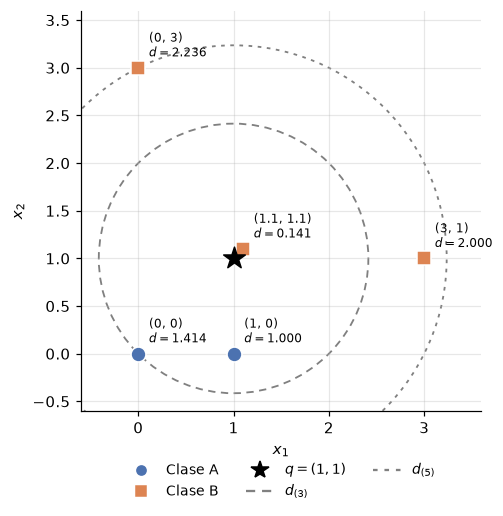

In [7]:
fig, ax = plt.subplots(figsize=(6.0, 4.8))

ax.scatter(Xk[yk == "A", 0], Xk[yk == "A", 1], s=95, marker="o",
           color="#4C72B0", edgecolor="white", zorder=4)
ax.scatter(Xk[yk == "B", 0], Xk[yk == "B", 1], s=95, marker="s",
           color="#DD8452", edgecolor="white", zorder=4)
ax.scatter(*q, s=220, marker="*", color="black", zorder=5)

for i in range(len(Xk)):
    ax.annotate(f"({Xk[i,0]:g}, {Xk[i,1]:g})\n$d={d[i]:.3f}$", Xk[i],
                textcoords="offset points", xytext=(7, 7), fontsize=8)

for k, estilo in [(3, (0, (4, 3))), (5, (0, (2, 3)))]:
    r = d[orden[k - 1]]
    ax.add_patch(plt.Circle(q, r, fill=False, ls=estilo, lw=1.2, color="gray"))

from matplotlib.lines import Line2D
manejadores = [
    Line2D([], [], marker="o", ls="", color="#4C72B0", label="Clase A"),
    Line2D([], [], marker="s", ls="", color="#DD8452", label="Clase B"),
    Line2D([], [], marker="*", ls="", color="black", markersize=12,
           label="$q=(1,1)$"),
    Line2D([], [], ls=(0, (4, 3)), color="gray", label="$d_{(3)}$"),
    Line2D([], [], ls=(0, (2, 3)), color="gray", label="$d_{(5)}$"),
]

ax.set_xlim(-0.6, 3.6)
ax.set_ylim(-0.6, 3.6)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_aspect("equal")
ax.legend(handles=manejadores, loc="upper center", bbox_to_anchor=(0.5, -0.10),
          ncol=3, fontsize=9, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "p2_manual.pdf", bbox_inches="tight")
plt.show()

## 2.2 Implementación con `make_moons`

Se generan $N=300$ observaciones con `noise=0.20` y `random_state=42`; se
separan 70 % para entrenamiento y 30 % para prueba, estratificando las clases.
Se entrenan tres clasificadores con $k\in\{1,5,15\}$ y se reporta la exactitud
en entrenamiento y en prueba.

**Qué mirar:** con $k=1$ la exactitud de entrenamiento es perfecta, señal de
memorización; la de prueba no es la mejor.

In [8]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=300, noise=0.20, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print("Total:", X.shape, "| clases:", np.bincount(y))
print("Train:", X_tr.shape, "| clases:", np.bincount(y_tr))
print("Test :", X_te.shape, "| clases:", np.bincount(y_te))

modelos = {}
print(f"\n{'k':>3} {'exactitud train':>16} {'exactitud test':>15}")
for k in (1, 5, 15):
    clf = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    acc_tr = accuracy_score(y_tr, clf.predict(X_tr))
    acc_te = accuracy_score(y_te, clf.predict(X_te))
    modelos[k] = clf
    print(f"{k:3d} {acc_tr:16.4f} {acc_te:15.4f}")

Total: (300, 2) | clases: [150 150]
Train: (210, 2) | clases: [105 105]
Test : (90, 2) | clases: [45 45]

  k  exactitud train  exactitud test
  1           1.0000          0.9333
  5           0.9571          0.9556
 15           0.9571          0.9333


### Explicación — Figura 2.2

Los puntos rellenos son de entrenamiento y los huecos de prueba. El color
indica la clase. La figura muestra que las dos lunas se solapan por el ruido
`noise=0.20`, así que ningún clasificador puede separarlas perfectamente.

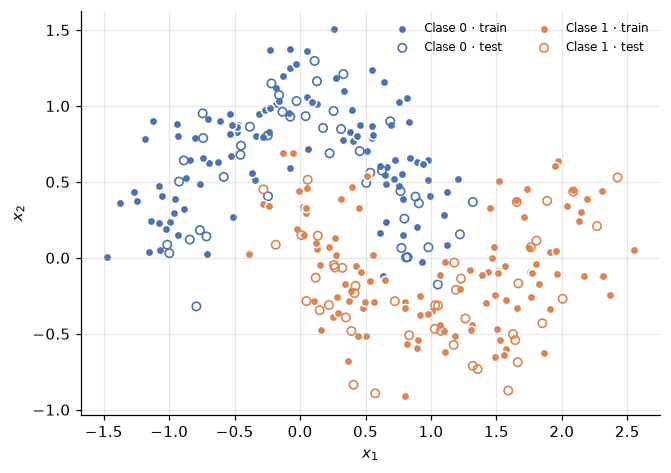

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 4.4))

for cls, color, nombre in [(0, "#4C72B0", "Clase 0"), (1, "#DD8452", "Clase 1")]:
    ax.scatter(X_tr[y_tr == cls, 0], X_tr[y_tr == cls, 1], s=30,
               color=color, edgecolor="white", label=f"{nombre} · train")
    ax.scatter(X_te[y_te == cls, 0], X_te[y_te == cls, 1], s=30,
               facecolor="none", edgecolor=color, lw=1.1, label=f"{nombre} · test")

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(fontsize=8, frameon=False, ncol=2, loc="upper right")
fig.tight_layout()
fig.savefig(FIG_DIR / "p2_datos.pdf", bbox_inches="tight")
plt.show()

### Explicación — Figura 2.3

Cada panel pinta la clase que predice el modelo en cada punto del plano
(región de decisión) y superpone los datos de entrenamiento.

- **$k=1$**: frontera quebrada, con islas alrededor de puntos ruidosos.
- **$k=15$**: frontera suave; el vecindario es amplio y promedia más.

**Qué mirar:** la frontera de $k=1$ rodea puntos individuales; la de $k=15$
ignora el detalle fino y corta las lunas de forma más limpia.

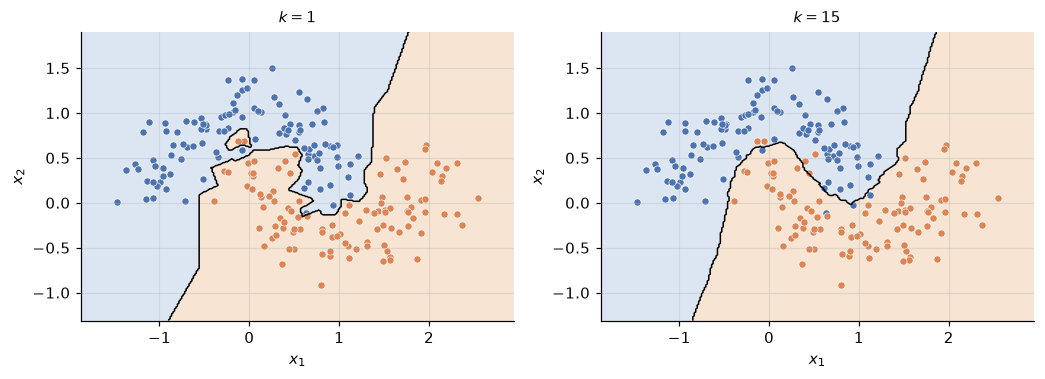

In [10]:
def regiones(ax, clf, X, y, titulo):
    x_min, x_max = X[:, 0].min() - 0.4, X[:, 0].max() + 0.4
    y_min, y_max = X[:, 1].min() - 0.4, X[:, 1].max() + 0.4
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5],
                colors=["#DCE6F2", "#F7E4D2"])
    ax.contour(xx, yy, Z, levels=[0.5], colors="black", linewidths=1.0)

    for cls, color in [(0, "#4C72B0"), (1, "#DD8452")]:
        ax.scatter(X[y == cls, 0], X[y == cls, 1], s=22,
                   color=color, edgecolor="white", lw=0.4)
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal")

fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2))
regiones(axes[0], modelos[1], X_tr, y_tr, "$k=1$")
regiones(axes[1], modelos[15], X_tr, y_tr, "$k=15$")
fig.tight_layout()
fig.savefig(FIG_DIR / "p2_regiones.pdf", bbox_inches="tight")
plt.show()

## 2.3 Interpretación

- **$k$ muy pequeño (1).** El vecindario es un solo punto: el modelo copia el
  ruido del entrenamiento. Exactitud de entrenamiento $1.0000$ y de prueba
  $0.9333$; la frontera tiene islas y esquinas. Es un caso de **alta varianza**.
- **$k$ muy grande (15).** El vecindario abarca una zona amplia: la frontera se
  suaviza y disminuye la varianza, pero aumenta el **sesgo**. Entrenamiento
  $0.9571$ y prueba $0.9333$; ya empieza a promediar puntos de la otra luna.
- **Mejor compromiso en esta partición: $k=5$.** Entrenamiento $0.9571$ y
  prueba $0.9556$, la exactitud de prueba más alta de las tres.

**Cuidado con la conclusión.** El conjunto de prueba tiene 90 observaciones:
un solo error cambia la exactitud en $1/90\approx1.11$ puntos porcentuales. La
diferencia entre $0.9333$ y $0.9556$ es de dos observaciones, así que no es
evidencia fuerte. Además, elegir $k$ mirando la prueba contamina la evaluación.

La selección formal de $k$ se hace con **validación** sobre el entrenamiento
(por ejemplo, validación cruzada estratificada de 5 pliegues): se elige el $k$
con mejor exactitud media de validación y el conjunto de prueba se usa una sola
vez, al final, para estimar el desempeño de generalización. Así la prueba no
participa en ninguna decisión del modelo.

---
# 3. Evaluación de un clasificador binario

Etiquetas verdaderas y predicciones del enunciado, con la clase $1$ como
positiva:

$$
y = [0,0,0,0,1,1,1,1,1,1],
\qquad
\hat{y} = [0,1,0,0,1,0,1,1,0,1].
$$

### Explicación — 3.1 Matriz de confusión

La matriz se escribe con las clases reales en las filas y las predichas en las
columnas. El orden es $(0,1)$ en ambas.

- $TP$: real $1$, predicho $1$.
- $TN$: real $0$, predicho $0$.
- $FP$: real $0$, predicho $1$ (falsa alarma).
- $FN$: real $1$, predicho $0$ (positivo no detectado).

**Qué mirar:** que la suma de las cuatro celdas sea 10 y que la diagonal
contenga los aciertos ($TP+TN=7$).

In [11]:
y_true = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

TP = int(np.sum((y_true == 1) & (y_pred == 1)))
TN = int(np.sum((y_true == 0) & (y_pred == 0)))
FP = int(np.sum((y_true == 0) & (y_pred == 1)))
FN = int(np.sum((y_true == 1) & (y_pred == 0)))

print("TP =", TP, "| TN =", TN, "| FP =", FP, "| FN =", FN)
print("Total =", TP + TN + FP + FN)

from sklearn.metrics import confusion_matrix
C = confusion_matrix(y_true, y_pred, labels=[0, 1])
print("\nconfusion_matrix (filas reales, columnas predichas):")
print(C)

TP = 4 | TN = 3 | FP = 1 | FN = 2
Total = 10

confusion_matrix (filas reales, columnas predichas):
[[3 1]
 [2 4]]


### Explicación — Figura 3.1

Mapa de calor de la matriz de confusión. La diagonal son los aciertos; fuera de
ella quedan la falsa alarma ($FP=1$) y los dos positivos no detectados
($FN=2$).

**Qué mirar:** la celda $(1,0)$ es la más costosa en este problema: son los
positivos que el clasificador deja pasar.

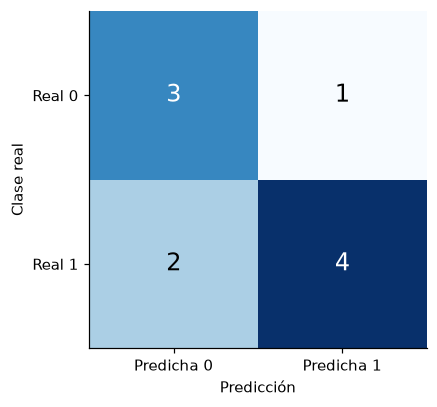

In [12]:
fig, ax = plt.subplots(figsize=(4.4, 3.8))
im = ax.imshow(C, cmap="Blues")

for i in range(2):
    for j in range(2):
        color = "white" if C[i, j] > C.max() / 2 else "black"
        ax.text(j, i, C[i, j], ha="center", va="center",
                fontsize=16, color=color)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Predicha 0", "Predicha 1"])
ax.set_yticks([0, 1])
ax.set_yticklabels(["Real 0", "Real 1"])
ax.set_xlabel("Predicción")
ax.set_ylabel("Clase real")
ax.grid(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "p3_matriz.pdf", bbox_inches="tight")
plt.show()

## 3.2 Métricas

$$
\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},
\qquad
\text{Precision}=\frac{TP}{TP+FP},
$$

$$
\text{Recall}=\frac{TP}{TP+FN},
\qquad
F_1=\frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}.
$$

- **Exactitud:** proporción total de aciertos; trata igual a las dos clases.
- **Precisión:** de lo que el modelo marca como positivo, cuánto lo es.
- **Recall (sensibilidad):** de los positivos reales, cuántos detecta.
- **$F_1$:** media armónica de precisión y recall; penaliza que una sea mucho
  mayor que la otra.

In [13]:
acc  = (TP + TN) / (TP + TN + FP + FN)
prec = TP / (TP + FP)
rec  = TP / (TP + FN)
f1   = 2 * prec * rec / (prec + rec)

print(f"Accuracy  = {acc:.4f}  = {TP + TN}/{TP + TN + FP + FN}")
print(f"Precision = {prec:.4f}  = {TP}/{TP + FP}")
print(f"Recall    = {rec:.4f}  = {TP}/{TP + FN}")
print(f"F1        = {f1:.4f}  = 8/11")

from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score)

print("\nVerificación con scikit-learn:")
print("accuracy_score :", f"{accuracy_score(y_true, y_pred):.4f}")
print("precision_score:", f"{precision_score(y_true, y_pred):.4f}")
print("recall_score   :", f"{recall_score(y_true, y_pred):.4f}")
print("f1_score       :", f"{f1_score(y_true, y_pred):.4f}")

Accuracy  = 0.7000  = 7/10
Precision = 0.8000  = 4/5
Recall    = 0.6667  = 4/6
F1        = 0.7273  = 8/11

Verificación con scikit-learn:
accuracy_score : 0.7000
precision_score: 0.8000
recall_score   : 0.6667
f1_score       : 0.7273


## 3.3 Verificación y análisis

Los valores coinciden con el cálculo manual:

| Métrica | Manual | scikit-learn |
|---------|--------|--------------|
| Accuracy | $7/10=0.7000$ | $0.7000$ |
| Precision | $4/5=0.8000$ | $0.8000$ |
| Recall | $4/6=0.6667$ | $0.6667$ |
| $F_1$ | $8/11=0.7273$ | $0.7273$ |

**Dos situaciones en las que la exactitud sola engaña.**

1. **Clases desbalanceadas.** Si 95 de 100 casos son negativos, un modelo que
   siempre predice 0 acierta 95 % y no detecta ningún positivo. La exactitud se
   ve excelente, pero el recall es 0. Abajo se comprueba.
2. **Costos asimétricos.** En tamizaje médico o detección de fraude, un $FN$
   (enfermo no detectado, fraude no bloqueado) suele costar mucho más que un
   $FP$ (examen adicional, revisión manual). La exactitud pondera ambos errores
   por igual, así que no refleja el costo real.

En ambos casos hay que reportar, como mínimo, la matriz de confusión,
precisión, recall y $F_1$; y comparar la exactitud con la del clasificador
trivial que siempre predice la clase mayoritaria (aquí, $6/10=0.60$).

In [14]:
y_imb = np.array([0] * 95 + [1] * 5)   # 95 negativos, 5 positivos
y_todo_cero = np.zeros_like(y_imb)     # predice siempre 0

print("Exactitud del modelo trivial:", f"{accuracy_score(y_imb, y_todo_cero):.2f}")
print("Recall del modelo trivial   :",
      f"{recall_score(y_imb, y_todo_cero, zero_division=0):.2f}")
print("Positivos detectados        :", int(np.sum((y_imb == 1) & (y_todo_cero == 1))), "de 5")

Exactitud del modelo trivial: 0.95
Recall del modelo trivial   : 0.00
Positivos detectados        : 0 de 5


## Resumen

1. La frontera $w^\top x+b=0$ divide el plano en dos semiplanos; el signo de
   $s(x)$ asigna la clase. Con $w=(1,2)$, $b=-3$: dos puntos van a $-1$ y dos a $+1$.
2. Tras una actualización del perceptrón, el margen de la observación corregida
   aumenta exactamente en $\eta(\lVert x_i\rVert^2+1)$; el aumento es fijo y no
   garantiza corregirla en un solo paso.
3. En el ejemplo numérico, $s=0$ obliga a actualizar: $w=(1,0.5)$, $b=0.5$ y el
   margen pasa de 0 a 3.
4. En k-NN, $k$ controla el tamaño del vecindario: $k=1$ da $B$, $k=3$ da $A$ y
   $k=5$ da $B$ para $q=(1,1)$.
5. Con `make_moons`, $k=1$ memoriza (train $1.0000$, test $0.9333$), $k=15$
   suaviza (test $0.9333$) y $k=5$ logra el mejor equilibrio (test $0.9556$).
   La elección formal de $k$ debe hacerse por validación, no con la prueba.
6. Matriz de confusión: $TP=4$, $TN=3$, $FP=1$, $FN=2$; accuracy $0.70$,
   precision $0.80$, recall $0.6667$ y $F_1=0.7273$.